# Задача 3. Предсказание стоимости медицинской страховки


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, GridSearchCV, KFold
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler, FunctionTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

pd.set_option('display.width', 200)
pd.set_option('display.max_columns', 30)
RANDOM_STATE = 42

## 1. Загрузка набора данных

In [3]:
import os

LOCAL_PATH = 'insurance.csv'
URL = 'https://raw.githubusercontent.com/stedy/Machine-Learning-with-R-datasets/master/insurance.csv'

if os.path.exists(LOCAL_PATH):
    # sep=None сам определяет разделитель (',' или ';' после сохранения в Excel)
    df = pd.read_csv(LOCAL_PATH, sep=None, engine='python', encoding='utf-8-sig')
    print('Загружен локальный файл', LOCAL_PATH)
else:
    df = pd.read_csv(URL)
    print('Загружено по ссылке', URL)

# приводим названия столбцов к единому виду
df.columns = df.columns.str.strip().str.lower()

# в некоторых версиях датасета целевой столбец называется expenses
df = df.rename(columns={'expenses': 'charges'})

# если числа записаны с запятой (27,9), переводим в числа
for col in ['age', 'bmi', 'children', 'charges']:
    if col in df.columns and not pd.api.types.is_numeric_dtype(df[col]):
        df[col] = pd.to_numeric(df[col].astype(str).str.replace(',', '.').str.strip())

# текстовые значения без лишних пробелов
for col in ['sex', 'smoker', 'region']:
    if col in df.columns:
        df[col] = df[col].astype(str).str.strip().str.lower()

required = ['age', 'sex', 'bmi', 'children', 'smoker', 'region', 'charges']
missing = [c for c in required if c not in df.columns]
if missing:
    raise ValueError(f'В файле нет столбцов {missing}. Найдены столбцы: {list(df.columns)}. '
                     'Проверьте, что это insurance.csv с Kaggle.')

print('Размер:', df.shape)
df.head()

Загружен локальный файл insurance.csv
Размер: (1338, 7)


,age,sex,bmi,children,smoker,region,charges
0,19,female,27.9,0,yes,southwest,16884.92
1,18,male,33.8,1,no,southeast,1725.55
2,28,male,33.0,3,no,southeast,4449.46
3,33,male,22.7,0,no,northwest,21984.47
4,32,male,28.9,0,no,northwest,3866.86


## 2. Исследование данных
Признаки:
- `age` — возраст;
- `sex` — пол;
- `bmi` — индекс массы тела;
- `children` — число детей;
- `smoker` — курит ли;
- `region` — регион США;
- `charges` — стоимость страховки (целевая переменная).

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   str    
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   str    
 5   region    1338 non-null   str    
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), str(3)
memory usage: 73.3 KB


In [5]:
df.describe()

,age,bmi,children,charges
count,1338.000000,1338.000000,1338.000000,1338.000000
mean,39.207025,30.665471,1.094918,13270.422414
std,14.049960,6.098382,1.205493,12110.011240
min,18.000000,16.000000,0.000000,1121.870000
25%,27.000000,26.300000,0.000000,4740.287500
50%,39.000000,30.400000,1.000000,9382.030000
75%,51.000000,34.700000,2.000000,16639.915000
max,64.000000,53.100000,5.000000,63770.430000


In [6]:
print('Пропуски по столбцам:')
print(df.isnull().sum())
print('\nДубликатов строк:', df.duplicated().sum())

Пропуски по столбцам:
age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64

Дубликатов строк: 1


In [7]:
for col in ['sex', 'smoker', 'region', 'children']:
    print(df[col].value_counts(), '\n')

sex
male      676
female    662
Name: count, dtype: int64 

smoker
no     1064
yes     274
Name: count, dtype: int64 

region
southeast    364
southwest    325
northwest    325
northeast    324
Name: count, dtype: int64 

children
0    574
1    324
2    240
3    157
4     25
5     18
Name: count, dtype: int64 



### Распределение целевой переменной

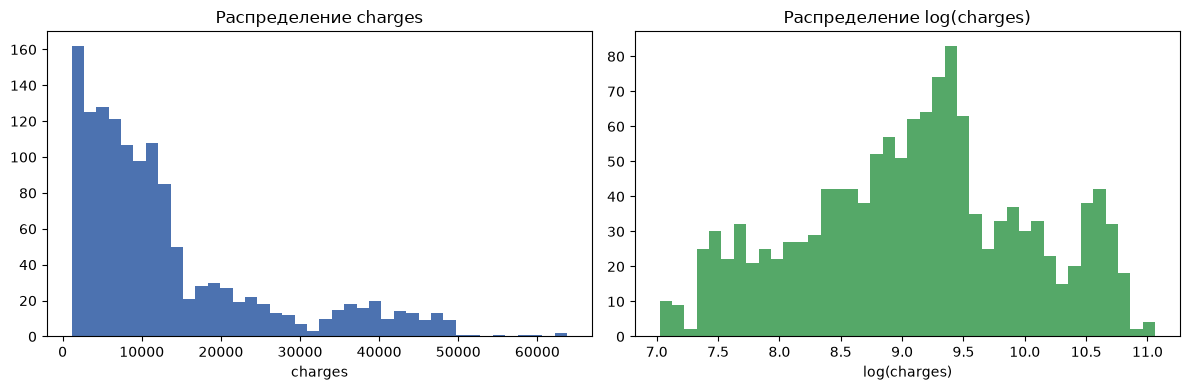

Асимметрия charges: 1.52


In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(df['charges'], bins=40, color='#4C72B0')
axes[0].set_title('Распределение charges')
axes[0].set_xlabel('charges')
axes[1].hist(np.log(df['charges']), bins=40, color='#55A868')
axes[1].set_title('Распределение log(charges)')
axes[1].set_xlabel('log(charges)')
plt.tight_layout()
plt.show()

print('Асимметрия charges:', round(df['charges'].skew(), 2))

### Влияние признаков на стоимость

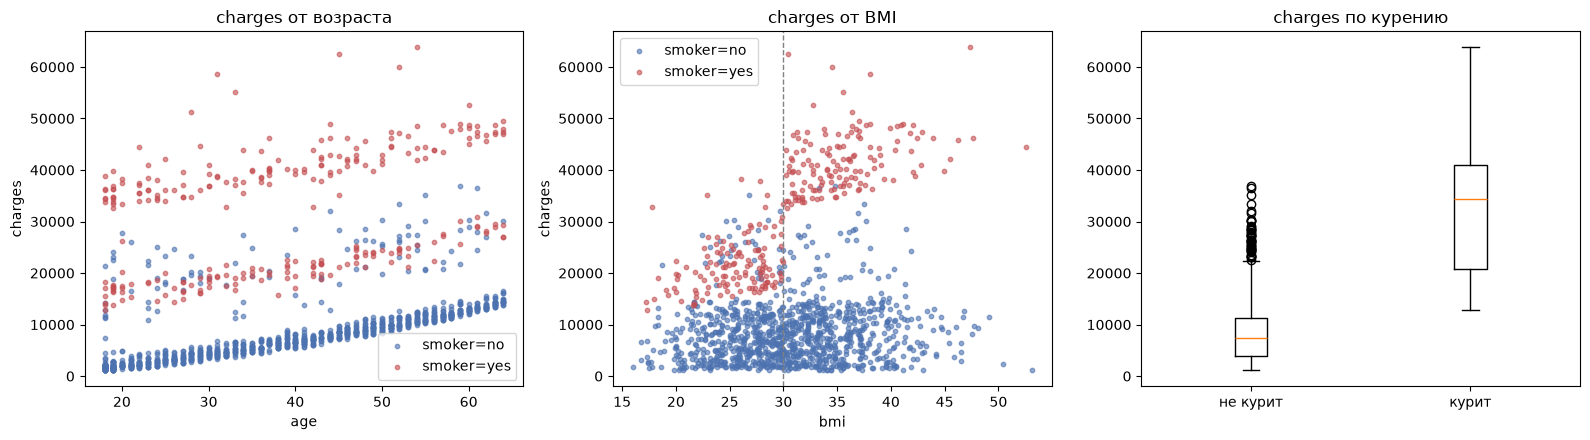

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

for status, color in [('no', '#4C72B0'), ('yes', '#C44E52')]:
    part = df[df['smoker'] == status]
    axes[0].scatter(part['age'], part['charges'], s=10, alpha=0.6, color=color, label=f'smoker={status}')
    axes[1].scatter(part['bmi'], part['charges'], s=10, alpha=0.6, color=color, label=f'smoker={status}')
axes[0].set_title('charges от возраста')
axes[0].set_xlabel('age')
axes[1].set_title('charges от BMI')
axes[1].set_xlabel('bmi')
axes[1].axvline(30, color='gray', ls='--', lw=1)
for ax in axes[:2]:
    ax.set_ylabel('charges')
    ax.legend()

groups = [df.loc[df['smoker'] == s, 'charges'] for s in ['no', 'yes']]
axes[2].boxplot(groups, tick_labels=['не курит', 'курит'])
axes[2].set_title('charges по курению')
plt.tight_layout()
plt.show()

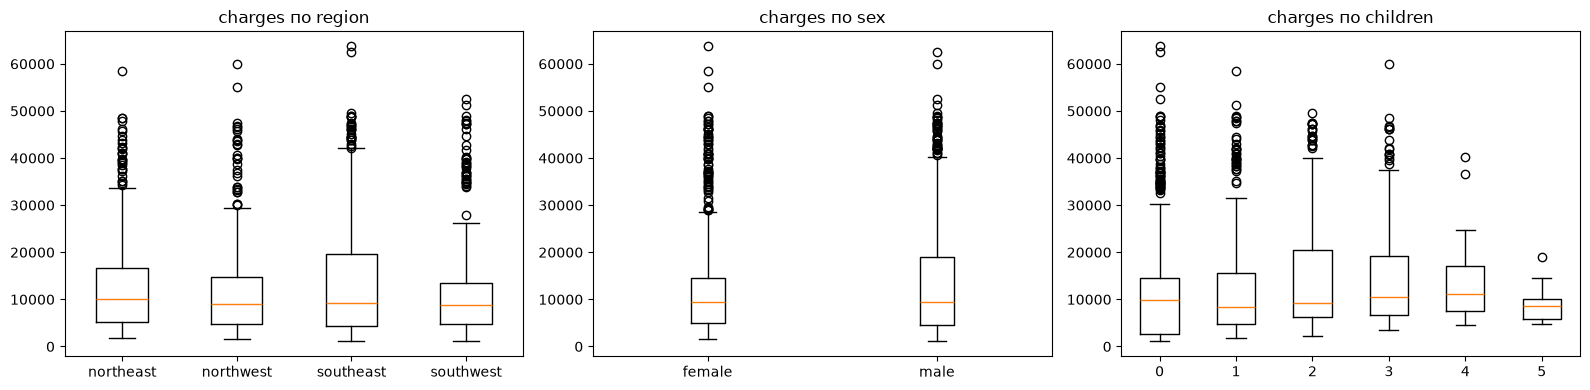

smoker
no      8434.0
yes    32050.0
Name: charges, dtype: float64
region
northeast    13406.0
northwest    12418.0
southeast    14735.0
southwest    12347.0
Name: charges, dtype: float64


In [10]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, col in zip(axes, ['region', 'sex', 'children']):
    cats = sorted(df[col].unique())
    ax.boxplot([df.loc[df[col] == c, 'charges'] for c in cats], tick_labels=[str(c) for c in cats])
    ax.set_title(f'charges по {col}')
plt.tight_layout()
plt.show()

print(df.groupby('smoker')['charges'].mean().round(0))
print(df.groupby('region')['charges'].mean().round(0))

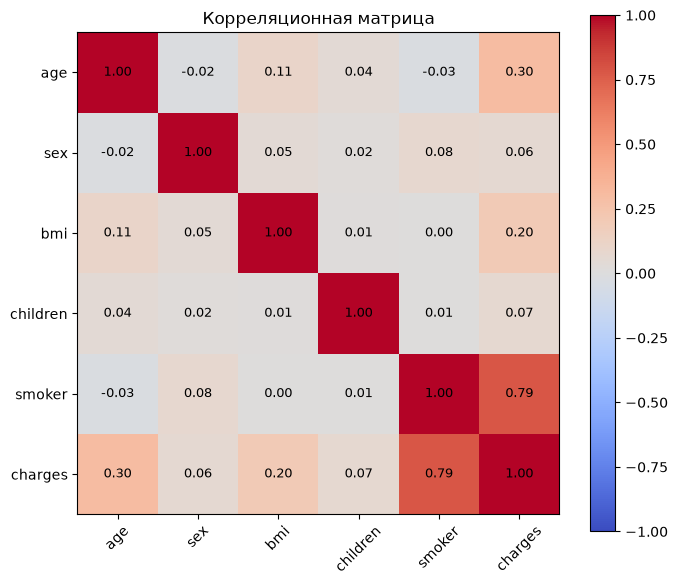

In [11]:
num = df.copy()
num['sex'] = (num['sex'] == 'male').astype(int)
num['smoker'] = (num['smoker'] == 'yes').astype(int)
corr = num.drop(columns='region').corr()

fig, ax = plt.subplots(figsize=(7, 6))
im = ax.imshow(corr, cmap='coolwarm', vmin=-1, vmax=1)
ax.set_xticks(range(len(corr)), corr.columns, rotation=45)
ax.set_yticks(range(len(corr)), corr.columns)
for i in range(len(corr)):
    for j in range(len(corr)):
        ax.text(j, i, f'{corr.iloc[i, j]:.2f}', ha='center', va='center', fontsize=9)
fig.colorbar(im)
ax.set_title('Корреляционная матрица')
plt.tight_layout()
plt.show()

## 3. Предварительная обработка данных


In [12]:
before = len(df)
df = df.drop_duplicates().reset_index(drop=True)
print(f'Удалено дубликатов: {before - len(df)}, осталось строк: {len(df)}')

X = df.drop(columns='charges')
y = df['charges']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=X['smoker'])
print('Обучающая выборка:', X_train.shape, ' Тестовая выборка:', X_test.shape)

Удалено дубликатов: 1, осталось строк: 1337
Обучающая выборка: (1069, 6)  Тестовая выборка: (268, 6)


In [14]:
def add_features(data):
    d = data.copy()
    smoker = (d['smoker'] == 'yes').astype(int)
    d['age2'] = d['age'] ** 2
    d['obese'] = (d['bmi'] >= 30).astype(int)
    d['smoker_bmi'] = smoker * d['bmi']
    d['smoker_obese'] = smoker * d['obese']
    return d

CAT = ['sex', 'smoker', 'region']
NUM_BASE = ['age', 'bmi', 'children']
NUM_EXT = NUM_BASE + ['age2', 'obese', 'smoker_bmi', 'smoker_obese']

def make_preprocessor(num_cols):
    return ColumnTransformer([
        ('num', StandardScaler(), num_cols),
        ('cat', OneHotEncoder(drop='first'), CAT),
    ])

feature_sets = {
    'базовые':      (FunctionTransformer(lambda d: d), NUM_BASE),
    'расширенные':  (FunctionTransformer(add_features), NUM_EXT),
}

add_features(X_train).head()

,age,sex,bmi,children,smoker,region,age2,obese,smoker_bmi,smoker_obese
367,42,female,25.0,2,no,northwest,1764,0,0.0,0
418,64,male,39.2,1,no,southeast,4096,1,0.0,0
938,53,male,29.5,0,no,southeast,2809,0,0.0,0
533,37,male,36.2,0,no,southeast,1369,1,0.0,0
354,18,female,38.3,0,no,southeast,324,1,0.0,0


## 4. Выбор метода построения модели регрессии


## 5. Выбор метрики качества (обоснование)


In [15]:
def rmse(y_true, y_pred):
    return np.sqrt(mean_squared_error(y_true, y_pred))

def evaluate(y_true, y_pred):
    return {'RMSE': rmse(y_true, y_pred),
            'MAE': mean_absolute_error(y_true, y_pred),
            'R2': r2_score(y_true, y_pred)}

## 6. Обучение и тестирование моделей с разными комбинациями параметров

In [16]:
alphas = [0.001, 0.01, 0.1, 1, 10, 100, 1000]

models = {
    'LinearRegression': (LinearRegression(), {'model__fit_intercept': [True, False]}),
    'Ridge':            (Ridge(random_state=RANDOM_STATE), {'model__alpha': alphas}),
    'Lasso':            (Lasso(max_iter=50000, random_state=RANDOM_STATE), {'model__alpha': alphas}),
}

cv = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
results = []      # итог по лучшей конфигурации каждой модели
all_cv = []       # все комбинации параметров
fitted = {}

for fs_name, (fe, num_cols) in feature_sets.items():
    for m_name, (estimator, grid) in models.items():
        pipe = Pipeline([
            ('features', fe),
            ('prep', make_preprocessor(num_cols)),
            ('model', estimator),
        ])
        gs = GridSearchCV(pipe, grid, cv=cv, scoring='neg_root_mean_squared_error')
        gs.fit(X_train, y_train)

        for params, score in zip(gs.cv_results_['params'], gs.cv_results_['mean_test_score']):
            all_cv.append({'Признаки': fs_name, 'Модель': m_name,
                           'Параметры': {k.replace('model__', ''): v for k, v in params.items()},
                           'CV RMSE': -score})

        y_pred = gs.predict(X_test)
        row = {'Признаки': fs_name, 'Модель': m_name,
               'Лучшие параметры': {k.replace('model__', ''): v for k, v in gs.best_params_.items()},
               'CV RMSE': -gs.best_score_}
        row.update({f'Test {k}': v for k, v in evaluate(y_test, y_pred).items()})
        results.append(row)
        fitted[(fs_name, m_name)] = gs.best_estimator_

print('Обучено моделей:', len(fitted), ' Проверено комбинаций параметров:', len(all_cv))

Обучено моделей: 6  Проверено комбинаций параметров: 32


### Все комбинации параметров (RMSE на кросс-валидации)

In [17]:
cv_table = pd.DataFrame(all_cv)
cv_table['Параметры'] = cv_table['Параметры'].astype(str)
cv_table.sort_values('CV RMSE').round(2).reset_index(drop=True)

,Признаки,Модель,Параметры,CV RMSE
0,расширенные,Lasso,{'alpha': 10},4599.55
1,расширенные,Lasso,{'alpha': 1},4601.62
2,расширенные,Ridge,{'alpha': 1},4601.88
3,расширенные,Ridge,{'alpha': 0.1},4602.25
4,расширенные,Lasso,{'alpha': 0.1},4602.27
5,расширенные,Ridge,{'alpha': 0.01},4602.34
6,расширенные,Lasso,{'alpha': 0.01},4602.35
7,расширенные,Ridge,{'alpha': 0.001},4602.35
8,расширенные,Lasso,{'alpha': 0.001},4602.35
9,расширенные,LinearRegression,{'fit_intercept': True},4602.35


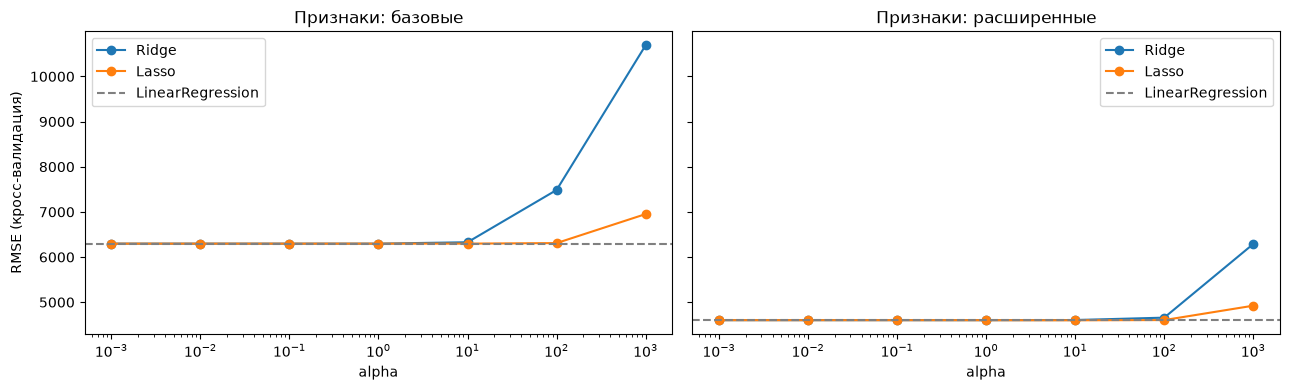

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4), sharey=True)
for ax, fs_name in zip(axes, feature_sets):
    for m_name in ['Ridge', 'Lasso']:
        part = [r for r in all_cv if r['Признаки'] == fs_name and r['Модель'] == m_name]
        ax.plot([r['Параметры']['alpha'] for r in part], [r['CV RMSE'] for r in part], marker='o', label=m_name)
    lr = min(r['CV RMSE'] for r in all_cv if r['Признаки'] == fs_name and r['Модель'] == 'LinearRegression')
    ax.axhline(lr, color='gray', ls='--', label='LinearRegression')
    ax.set_xscale('log')
    ax.set_xlabel('alpha')
    ax.set_title(f'Признаки: {fs_name}')
    ax.legend()
axes[0].set_ylabel('RMSE (кросс-валидация)')
plt.tight_layout()
plt.show()

## 7. Оценка качества вариантов модели по выбранной метрике

In [19]:
res = pd.DataFrame(results)
res['Лучшие параметры'] = res['Лучшие параметры'].astype(str)
res = res.sort_values('Test RMSE').reset_index(drop=True)
res.round({'CV RMSE': 2, 'Test RMSE': 2, 'Test MAE': 2, 'Test R2': 4})

,Признаки,Модель,Лучшие параметры,CV RMSE,Test RMSE,Test MAE,Test R2
0,расширенные,Lasso,{'alpha': 10},4599.55,3352.71,2000.50,0.9220
1,расширенные,Ridge,{'alpha': 1},4601.88,3366.25,2004.09,0.9214
2,расширенные,LinearRegression,{'fit_intercept': True},4602.35,3372.11,2006.81,0.9211
3,базовые,Lasso,{'alpha': 1},6297.04,5085.79,3592.20,0.8206
4,базовые,LinearRegression,{'fit_intercept': True},6297.05,5086.14,3591.96,0.8205
5,базовые,Ridge,{'alpha': 0.1},6297.02,5086.34,3592.94,0.8205


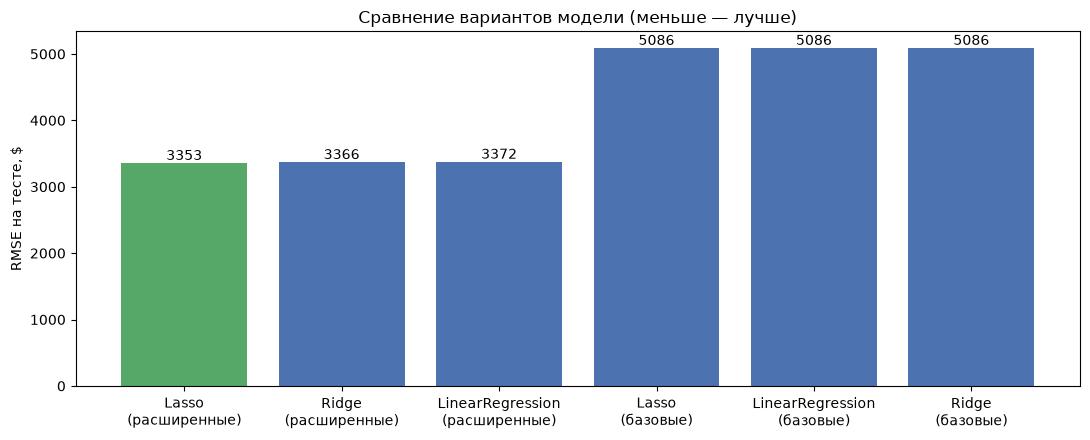

In [20]:
labels = [f"{r['Модель']}\n({r['Признаки']})" for _, r in res.iterrows()]
fig, ax = plt.subplots(figsize=(11, 4.5))
bars = ax.bar(labels, res['Test RMSE'], color=['#55A868'] + ['#4C72B0'] * (len(res) - 1))
ax.bar_label(bars, fmt='%.0f')
ax.set_ylabel('RMSE на тесте, $')
ax.set_title('Сравнение вариантов модели (меньше — лучше)')
plt.tight_layout()
plt.show()

In [21]:
best = res.iloc[0]
best_model = fitted[(best['Признаки'], best['Модель'])]
print('Лучшая модель:', best['Модель'])
print('Набор признаков:', best['Признаки'])
print('Параметры:', best['Лучшие параметры'])
print(f"Test RMSE = {best['Test RMSE']:.2f}, MAE = {best['Test MAE']:.2f}, R2 = {best['Test R2']:.4f}")

worst = res.iloc[-1]
print(f"\nХудший вариант: {worst['Модель']} ({worst['Признаки']}), RMSE = {worst['Test RMSE']:.2f}")
print(f"Улучшение RMSE: {(1 - best['Test RMSE'] / worst['Test RMSE']) * 100:.1f}%")

Лучшая модель: Lasso
Набор признаков: расширенные
Параметры: {'alpha': 10}
Test RMSE = 3352.71, MAE = 2000.50, R2 = 0.9220

Худший вариант: Ridge (базовые), RMSE = 5086.34
Улучшение RMSE: 34.1%


### Коэффициенты лучшей модели

In [22]:
prep = best_model.named_steps['prep']
coef = pd.Series(best_model.named_steps['model'].coef_, index=prep.get_feature_names_out())
coef = coef.reindex(coef.abs().sort_values(ascending=False).index)
print('Свободный член:', round(best_model.named_steps['model'].intercept_, 2))
coef.round(2).to_frame('Коэффициент')

Свободный член: 14281.75


,Коэффициент
num__smoker_bmi,6544.84
num__smoker_obese,4645.38
num__age2,3661.97
cat__region_southwest,-1353.43
num__children,877.86
cat__region_southeast,-725.88
cat__sex_male,-660.01
cat__region_northwest,-269.43
num__obese,53.25
num__bmi,-11.70


## 8. Прогноз целевого показателя лучшей моделью
Горизонт прогноза для этой задачи — новые клиенты, которых модель не видела при обучении. Сначала показываем прогноз на тестовой выборке, затем на нескольких новых клиентах.

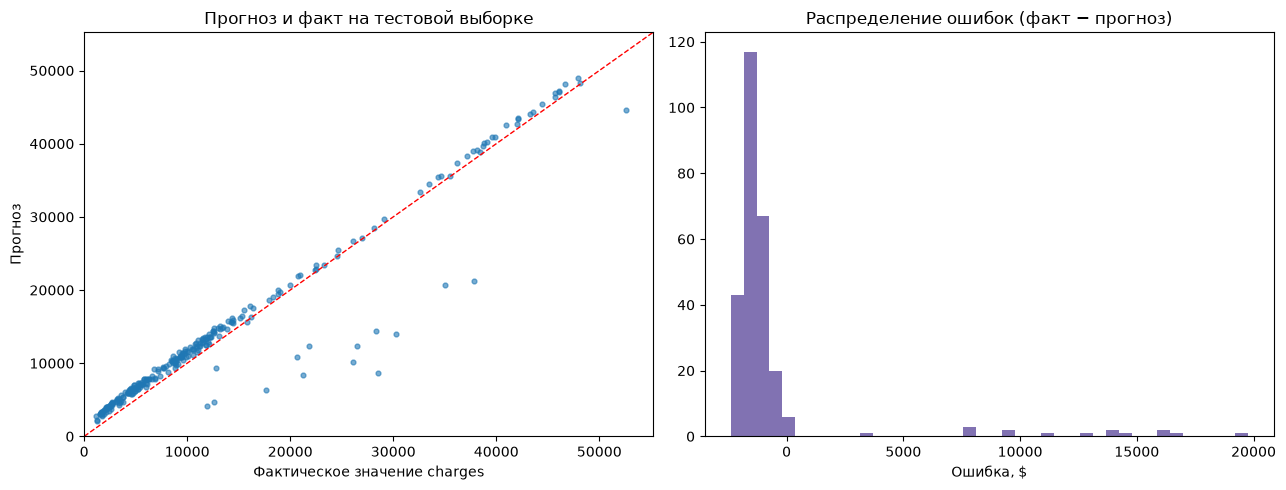

,age,sex,bmi,children,smoker,region,charges (факт),charges (прогноз),ошибка
575,58,female,27.2,0,no,northwest,12222.90,13633.40,-1410.50
931,46,male,25.8,5,no,southwest,10096.97,11548.44,-1451.47
955,54,male,30.8,1,yes,southeast,41999.52,42736.05,-736.53
144,30,male,28.7,3,yes,northwest,20745.99,21946.70,-1200.71
683,33,female,18.5,1,no,southwest,4766.02,5910.43,-1144.41
632,40,male,22.7,2,no,northeast,7173.36,9000.66,-1827.30
613,20,female,33.0,0,no,southeast,1880.07,3633.17,-1753.10
1100,53,male,28.6,3,no,southwest,11253.42,12310.78,-1057.36
701,53,male,41.5,0,no,southeast,9504.31,10791.33,-1287.02
968,39,female,34.3,5,no,southeast,8596.83,10991.46,-2394.63


In [23]:
y_pred_best = best_model.predict(X_test)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].scatter(y_test, y_pred_best, s=12, alpha=0.6)
lim = [0, max(y_test.max(), y_pred_best.max()) * 1.05]
axes[0].plot(lim, lim, 'r--', lw=1)
axes[0].set_xlim(lim); axes[0].set_ylim(lim)
axes[0].set_xlabel('Фактическое значение charges')
axes[0].set_ylabel('Прогноз')
axes[0].set_title('Прогноз и факт на тестовой выборке')

resid = y_test - y_pred_best
axes[1].hist(resid, bins=40, color='#8172B2')
axes[1].set_title('Распределение ошибок (факт − прогноз)')
axes[1].set_xlabel('Ошибка, $')
plt.tight_layout()
plt.show()

comparison = X_test.copy()
comparison['charges (факт)'] = y_test.round(2)
comparison['charges (прогноз)'] = y_pred_best.round(2)
comparison['ошибка'] = (comparison['charges (факт)'] - comparison['charges (прогноз)']).round(2)
comparison.head(15)

In [24]:
new_clients = pd.DataFrame([
    {'age': 25, 'sex': 'female', 'bmi': 22.0, 'children': 0, 'smoker': 'no',  'region': 'northeast'},
    {'age': 40, 'sex': 'male',   'bmi': 28.5, 'children': 2, 'smoker': 'no',  'region': 'southeast'},
    {'age': 40, 'sex': 'male',   'bmi': 28.5, 'children': 2, 'smoker': 'yes', 'region': 'southeast'},
    {'age': 55, 'sex': 'female', 'bmi': 33.0, 'children': 1, 'smoker': 'yes', 'region': 'northwest'},
    {'age': 60, 'sex': 'male',   'bmi': 31.0, 'children': 3, 'smoker': 'no',  'region': 'southwest'},
])
new_clients['Прогноз charges, $'] = best_model.predict(new_clients).round(2)
new_clients

,age,sex,bmi,children,smoker,region,"Прогноз charges, $"
0,25,female,22.0,0,no,northeast,5005.10
1,40,male,28.5,2,no,southeast,8263.62
2,40,male,28.5,2,yes,southeast,22921.28
3,55,female,33.0,1,yes,northwest,45334.24
4,60,male,31.0,3,no,southwest,14985.51
